# Phan Tich Loi Suat Co Phieu BSR va VN-Index

Notebook nay thuc hien toan bo phan tich theo yeu cau bai tap nhom:

1. **Phan 1** -- Phan tich hoi quy tuyen tinh don gian (Beta CAPM)
2. **Phan 2** -- Phan tich Volatility Clustering
3. **Phan 3** -- Mo hinh GARCH(1,1)

**Phan cong:** Quang Minh (1.1, 1.2) . Tuan Anh (1.3, 1.4) . Truc (2.1-2.4) . Thuy (3.1, 3.2) . Phong (3.3, 3.4)


In [1]:
# Setup
from pathlib import Path
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.dates as mdates
import statsmodels.api as sm
from scipy import stats as sp_stats
from scipy.stats import t as t_dist
from arch import arch_model

DATA_DIR = Path("data")
plt.rcParams.update({
    "figure.figsize": (13, 4), "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
})
BLUE, RED, GREEN = "#1f77b4", "#d62728", "#2ca02c"
print("Setup OK")

Setup OK


# PHAN 1 -- PHAN TICH HOI QUY DON GIAN

Phan nay nghien cuu moi quan he giua loi suat BSR va loi suat VN-Index thong qua mo hinh Simple Linear Regression.


## 1.1. Du lieu va bien nghien cuu -- Quang Minh

### Nguon va pham vi du lieu

| Muc | Chi tiet |
|-----|----------|
| **Co phieu (Y)** | BSR -- Cong ty Co phan Loc Hoa dau Binh Son (HOSE) |
| **Chi so (X)** | VN-Index -- Chi so gia thi truong chung khoan HOSE |
| **Thoi gian** | 02/01/2024 den 25/09/2026 |
| **Tan suat** | Hang ngay (daily), theo ngay giao dich |
| **Loai gia** | Gia dong cua (*closing price*), cot `Price` tren Investing.com |
| **Nguon** | Investing.com |

### Cong thuc log-return

$$r_t = \ln\!\left(\frac{P_t}{P_{t-1}}\right)$$

- $P_t$: gia dong cua ngay $t$
- $r_t$: log-return ngay $t$ (don vi: ty le thap phan)
- N gia cho N-1 returns


In [2]:
# 1.1 -- Load prices and compute log-returns
prices = pd.read_csv(DATA_DIR / "cleaned_aligned_prices.csv", parse_dates=["date"])
print(f"Loaded {len(prices)} aligned price observations")
print(f"Period: {prices['date'].min().date()} -> {prices['date'].max().date()}")

# Compute log-returns
df = prices.copy()
df["BSR_log_return"]     = np.log(df["BSR"]     / df["BSR"].shift(1))
df["VNINDEX_log_return"] = np.log(df["VNINDEX"] / df["VNINDEX"].shift(1))
df = df.dropna().reset_index(drop=True)

N = len(df)
print(f"N = {N} log-returns (from {N+1} prices)")
print()

# Descriptive statistics
desc = df[["BSR_log_return", "VNINDEX_log_return"]].describe().T
desc.index = ["BSR log-return", "VN-Index log-return"]
print("=== Descriptive Statistics ===")
print(desc[["mean", "std", "min", "max"]].round(6).to_string())
print()
print(f"BSR daily mean return:  {df['BSR_log_return'].mean()*100:.4f}%")
print(f"BSR daily std:          {df['BSR_log_return'].std()*100:.4f}%")
print(f"VN-Index daily std:     {df['VNINDEX_log_return'].std()*100:.4f}%")

Loaded 670 aligned price observations
Period: 2024-01-02 -> 2026-09-25
N = 669 log-returns (from 670 prices)

=== Descriptive Statistics ===
                         mean       std       min       max
BSR log-return       0.001494  0.026956 -0.072377  0.076936
VN-Index log-return  0.000681  0.011722 -0.069102  0.065469

BSR daily mean return:  0.1494%
BSR daily std:          2.6956%
VN-Index daily std:     1.1722%


## 1.2. Phuong phap Simple Linear Regression -- Quang Minh

### Mo hinh

$$R_{BSR,t} = \alpha + \beta \cdot R_{VNINDEX,t} + \varepsilon_t$$

### Giai thich cac thanh phan

| Ky hieu | Ten | Y nghia |
|---------|-----|---------|
| $R_{BSR,t}$ | Bien phu thuoc (Y) | Log-return cua BSR tai ngay $t$ |
| $R_{VNINDEX,t}$ | Bien doc lap (X) | Log-return cua VN-Index tai ngay $t$ |
| $\alpha$ | Intercept | Phan loi suat trung binh cua BSR **khong** phu thuoc vao thi truong |
| $\beta$ | He so Beta | Muc do nhay cam cua BSR voi bien dong thi truong: VN-Index tang 1% thi BSR tang trung binh $\beta$% |
| $\varepsilon_t$ | Sai so ngau nhien | Phan bien dong cua BSR **khong** duoc thi truong giai thich (rui ro dac thu) |

### Phuong phap uoc luong (OLS)

$$\min_{\alpha,\,\beta} \sum_{t=1}^{N} \varepsilon_t^2 = \sum_{t=1}^{N} \bigl(R_{BSR,t} - \alpha - \beta \cdot R_{VNINDEX,t}\bigr)^2$$

> **Luu y mo hinh don gian hoa:** Bai nay dung log-return tho thay vi *excess return*
> ($R - r_f$). Do lai suat phi rui ro ($r_f$) Viet Nam khong duoc chuan hoa theo ngay
> va thuong rat nho so voi bien dong thi truong, su khac biet la khong dang ke.
> Beta va $R^2$ khong thay doi; chi intercept $\alpha$ bi dich nho.


## 1.3. Ket qua hoi quy -- Tuan Anh


In [3]:
# 1.3 -- OLS regression (statsmodels)
X = sm.add_constant(df["VNINDEX_log_return"])
y = df["BSR_log_return"]
model = sm.OLS(y, X).fit()
print(model.summary())

alpha_val = model.params["const"]
beta_val  = model.params["VNINDEX_log_return"]
R2        = model.rsquared

ci = model.conf_int(alpha=0.05)
beta_ci_lo, beta_ci_hi = ci.loc["VNINDEX_log_return"]

print("\n=== Summary ===")
print(f"alpha = {alpha_val:.6f}")
print(f"beta  = {beta_val:.6f}  (CI 95%: [{beta_ci_lo:.4f}, {beta_ci_hi:.4f}])")
print(f"R2    = {R2:.4f}")
print(f"N     = {N}")

                            OLS Regression Results                            
Dep. Variable:         BSR_log_return   R-squared:                       0.170
Model:                            OLS   Adj. R-squared:                  0.169
Method:                 Least Squares   F-statistic:                     137.0
Date:                Wed, 30 Sep 2026   Prob (F-statistic):           6.51e-29
Time:                        18:51:42   Log-Likelihood:                 1531.2
No. Observations:                 669   AIC:                            -3058.
Df Residuals:                     667   BIC:                            -3049.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                  0.0008      0

In [4]:
# 1.3 -- Test beta != 1
beta_se = model.bse["VNINDEX_log_return"]
t_vs1   = (beta_val - 1) / beta_se
p_vs1   = 2 * t_dist.sf(abs(t_vs1), df=N-2)
print(f"Test H0: beta = 0  ->  t={model.tvalues['VNINDEX_log_return']:.4f}, p={model.pvalues['VNINDEX_log_return']:.2e}")
print(f"Test H0: beta = 1  ->  t={t_vs1:.4f}, p={p_vs1:.4f}")
if p_vs1 > 0.05:
    print("  -> Cannot reject H0 (beta=1) at 5% level")
else:
    print("  -> Reject H0 (beta=1) at 5% level")

Test H0: beta = 0  ->  t=11.7048, p=6.51e-29
Test H0: beta = 1  ->  t=-0.6251, p=0.5321
  -> Cannot reject H0 (beta=1) at 5% level


In [5]:
# 1.3 -- Cross-check with scipy (doi chieu doc lap)
slope, intercept, r_val, p_lr, se_lr = sp_stats.linregress(
    df["VNINDEX_log_return"], df["BSR_log_return"])
print("[scipy linregress cross-check]")
print(f"  beta  = {slope:.6f}")
print(f"  alpha = {intercept:.6f}")
print(f"  R2    = {r_val**2:.4f}")
print("  -> Matches statsmodels results" if abs(slope - beta_val) < 1e-8 else "  -> MISMATCH!")

[scipy linregress cross-check]
  beta  = 0.949304
  alpha = 0.000848
  R2    = 0.1704
  -> Matches statsmodels results


## 1.4. Dien giai Beta theo CAPM -- Tuan Anh

### Bon truong hop Beta

| Truong hop | Y nghia |
|-----------|---------|
| $\beta > 1$ | Co phieu **bien dong manh hon** thi truong |
| $\beta = 1$ | Co phieu **bien dong cung muc** voi thi truong |
| $0 < \beta < 1$ | Bien dong cung chieu nhung **thap hon** thi truong |
| $\beta < 0$ | Bien dong **nguoc chieu** thi truong |


Beta = 0.9493  (CI 95%: [0.7901, 1.1086])
-> beta ~ 1: BSR bien dong GAN BANG thi truong

R2 = 0.1704
  Rui ro he thong (VN-Index giai thich): 17.0%
  Rui ro dac thu (rieng BSR):            83.0%

Y nghia: khi VN-Index tang/giam 1%, BSR tang/giam trung binh 0.95%


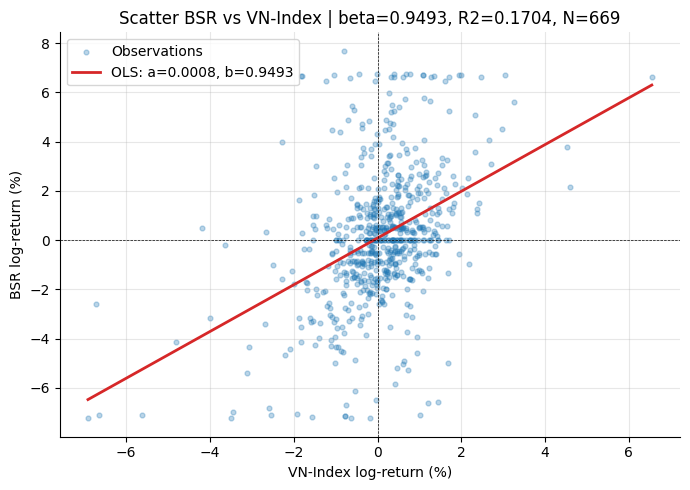


=== Han che ===
1. Khong dung excess return (khong tru r_f)
2. Beta phu thuoc ky mau
3. Gia dinh CAPM: thi truong hieu qua, da dang hoa hoan hao
4. Mo hinh mot nhan to: bo qua quy mo, gia tri, momentum


In [6]:
# 1.4 -- CAPM beta interpretation
print(f"Beta = {beta_val:.4f}  (CI 95%: [{beta_ci_lo:.4f}, {beta_ci_hi:.4f}])")

if beta_val > 1:
    print("-> beta > 1: BSR bien dong MANH HON thi truong")
elif abs(beta_val - 1) < beta_se:
    print("-> beta ~ 1: BSR bien dong GAN BANG thi truong")
elif beta_val > 0:
    print("-> 0 < beta < 1: BSR cung chieu nhung THAP HON thi truong")
else:
    print("-> beta < 0: BSR bien dong NGUOC CHIEU thi truong")

print(f"\nR2 = {R2:.4f}")
print(f"  Rui ro he thong (VN-Index giai thich): {R2*100:.1f}%")
print(f"  Rui ro dac thu (rieng BSR):            {(1-R2)*100:.1f}%")
print(f"\nY nghia: khi VN-Index tang/giam 1%, BSR tang/giam trung binh {beta_val:.2f}%")

# Scatter plot
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df["VNINDEX_log_return"]*100, df["BSR_log_return"]*100,
           alpha=0.3, s=12, color=BLUE, label="Observations")
xr = np.linspace(df["VNINDEX_log_return"].min(), df["VNINDEX_log_return"].max(), 200)
ax.plot(xr*100, (alpha_val + beta_val*xr)*100, color=RED, lw=2,
        label=f"OLS: a={alpha_val:.4f}, b={beta_val:.4f}")
ax.axhline(0, color="black", lw=0.5, ls="--")
ax.axvline(0, color="black", lw=0.5, ls="--")
ax.set_xlabel("VN-Index log-return (%)")
ax.set_ylabel("BSR log-return (%)")
ax.set_title(f"Scatter BSR vs VN-Index | beta={beta_val:.4f}, R2={R2:.4f}, N={N}")
ax.legend(); plt.tight_layout(); plt.show()

print("\n=== Han che ===")
print("1. Khong dung excess return (khong tru r_f)")
print("2. Beta phu thuoc ky mau")
print("3. Gia dinh CAPM: thi truong hieu qua, da dang hoa hoan hao")
print("4. Mo hinh mot nhan to: bo qua quy mo, gia tri, momentum")

# PHAN 2 -- PHAN TICH VOLATILITY CLUSTERING

Phan nay phan tich dac tinh bien dong theo thoi gian cua chuoi BSR log-return.


## 2.1. Chuoi BSR Log-return -- Truc

Chuoi BSR log-return dung trong phan nay la **cung bo du lieu voi Phan 1** (tinh truc tiep tu `cleaned_aligned_prices.csv`).


In [7]:
# 2.1 -- BSR return series stats
bsr_r = df["BSR_log_return"]
print(f"N = {N} observations")
print(f"Period: {df['date'].min().date()} -> {df['date'].max().date()}")
print()
print("=== Descriptive Statistics (BSR log-return) ===")
print(f"  Mean:           {bsr_r.mean():.6f}  ({bsr_r.mean()*100:.4f}%/day)")
print(f"  Std:            {bsr_r.std():.6f}  ({bsr_r.std()*100:.4f}%/day)")
print(f"  Min:            {bsr_r.min():.6f}  ({bsr_r.min()*100:.4f}%)")
print(f"  Max:            {bsr_r.max():.6f}  ({bsr_r.max()*100:.4f}%)")
print(f"  Skewness:       {bsr_r.skew():.4f}")
print(f"  Excess Kurtosis:{bsr_r.kurt():.4f}")
print()
if abs(bsr_r.skew()) < 0.5:
    print("Skewness ~ 0: phan phoi gan doi xung")
if bsr_r.kurt() > 0:
    print("Excess kurtosis > 0: duoi day hon normal (leptokurtic), dien hinh chuoi tai chinh")

N = 669 observations
Period: 2024-01-03 -> 2026-09-25

=== Descriptive Statistics (BSR log-return) ===
  Mean:           0.001494  (0.1494%/day)
  Std:            0.026956  (2.6956%/day)
  Min:            -0.072377  (-7.2377%)
  Max:            0.076936  (7.6936%)
  Skewness:       0.0579
  Excess Kurtosis:0.9488

Skewness ~ 0: phan phoi gan doi xung
Excess kurtosis > 0: duoi day hon normal (leptokurtic), dien hinh chuoi tai chinh


## 2.2. Bieu do chuoi thoi gian -- Truc


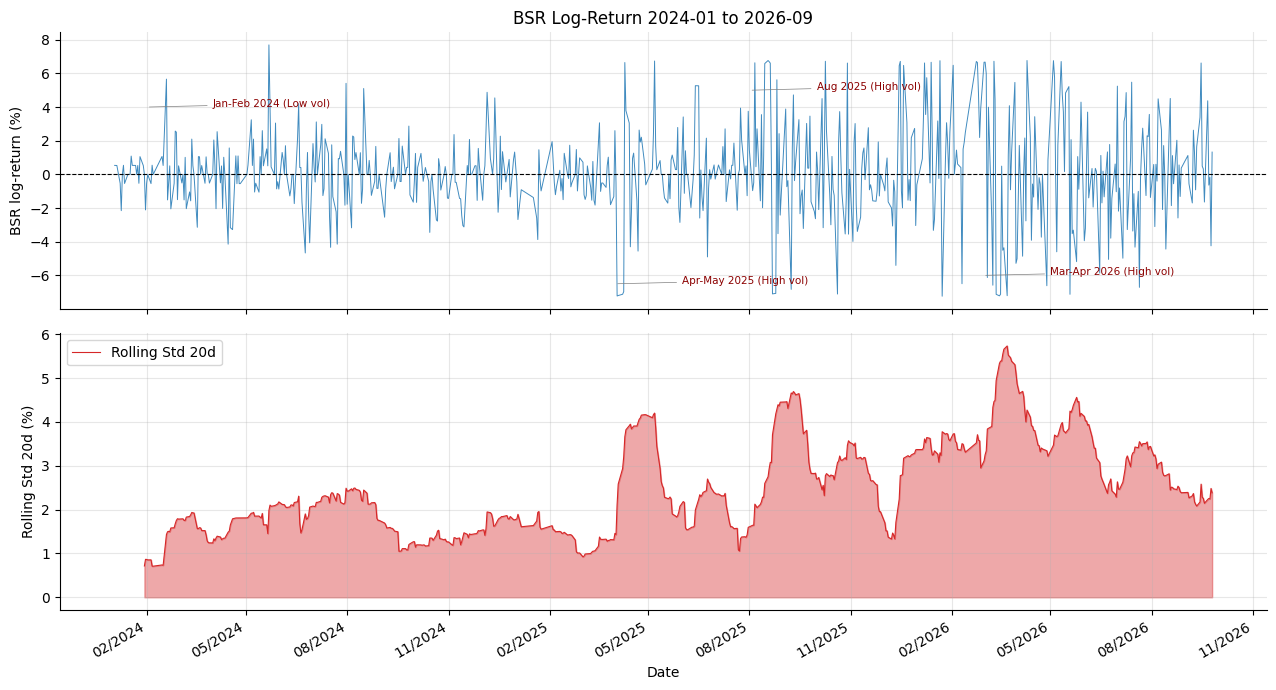


=== Notable Periods ===
High vol days (>3.5%/day): 123
  Range: 2025-04-10 -> 2026-07-28
Low vol days (<1.2%/day):  45
  Range: 2024-01-30 -> 2025-07-23


In [8]:
# 2.2 -- Time-series plot + rolling std
df["rolling_std_20"] = df["BSR_log_return"].rolling(20).std()

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)

# Panel 1: BSR log-return
ax1 = axes[0]
ax1.plot(df["date"], df["BSR_log_return"]*100, lw=0.7, color=BLUE, alpha=0.85)
ax1.axhline(0, color="black", lw=0.8, ls="--")
ax1.set_ylabel("BSR log-return (%)")
ax1.set_title("BSR Log-Return 2024-01 to 2026-09")

# Annotate notable periods
notable = [
    ("2025-04", "Apr-May 2025 (High vol)", -6.5),
    ("2025-08", "Aug 2025 (High vol)",       5.0),
    ("2026-03", "Mar-Apr 2026 (High vol)",  -6.0),
    ("2024-02", "Jan-Feb 2024 (Low vol)",    4.0),
]
for ds, label, yp in notable:
    xd = pd.Timestamp(ds)
    ax1.annotate(label, xy=(xd, yp),
                 xytext=(xd + pd.DateOffset(months=2), yp),
                 fontsize=7.5, color="darkred",
                 arrowprops=dict(arrowstyle="-", color="gray", lw=0.5))

# Panel 2: rolling std 20d
ax2 = axes[1]
ax2.fill_between(df["date"], df["rolling_std_20"]*100, alpha=0.4, color=RED)
ax2.plot(df["date"], df["rolling_std_20"]*100, lw=0.8, color=RED, label="Rolling Std 20d")
ax2.set_ylabel("Rolling Std 20d (%)")
ax2.set_xlabel("Date")
ax2.legend(loc="upper left")

for ax in axes:
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
plt.gcf().autofmt_xdate()
plt.tight_layout(); plt.show()

# Identify high/low vol periods
print("\n=== Notable Periods ===")
high_vol = df[df["rolling_std_20"] > 0.035][["date","rolling_std_20"]]
low_vol  = df[df["rolling_std_20"] < 0.012][["date","rolling_std_20"]]
print(f"High vol days (>3.5%/day): {len(high_vol)}")
if not high_vol.empty:
    print(f"  Range: {high_vol['date'].min().date()} -> {high_vol['date'].max().date()}")
print(f"Low vol days (<1.2%/day):  {len(low_vol)}")
if not low_vol.empty:
    print(f"  Range: {low_vol['date'].min().date()} -> {low_vol['date'].max().date()}")

## 2.3. Volatility Clustering -- Truc

**Volatility clustering** la hien tuong: *bien dong lon co xu huong tiep noi boi bien dong lon, va bien dong nho tiep noi boi bien dong nho.*

### Y nghia voi financial risk

> Rui ro **khong co dinh** theo thoi gian. Neu dung mot do lech chuan co dinh (std toan mau)
> de do rui ro, ta se **uoc luong sai**: underestimate risk trong giai doan bien dong cao,
> overestimate risk trong giai doan yen tinh. Dieu nay anh huong truc tiep den VaR, margin call,
> va quan tri danh muc.


ARCH-LM test (nlags=5)
  LM statistic = 123.9378
  p-value      = 0.000000
  -> Reject H0 (no ARCH effects) -> ARCH effects present -> volatility clustering confirmed


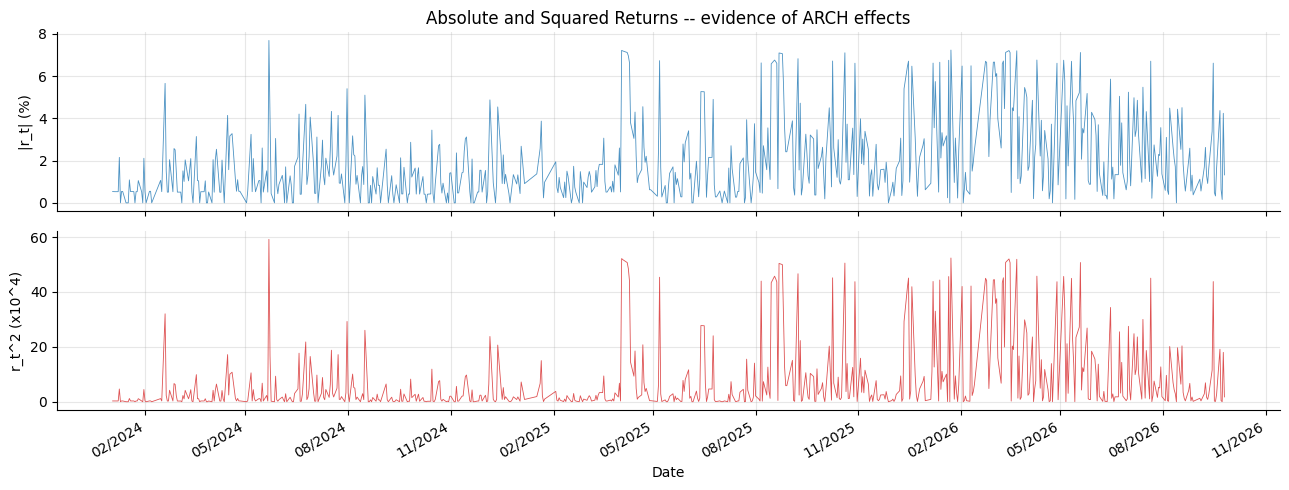

In [9]:
# 2.3 -- ARCH-LM test + absolute/squared returns
from statsmodels.stats.diagnostic import het_arch

r_series = df["BSR_log_return"].dropna().values
lm_stat, lm_pval, f_stat, f_pval = het_arch(r_series, nlags=5)
print("ARCH-LM test (nlags=5)")
print(f"  LM statistic = {lm_stat:.4f}")
print(f"  p-value      = {lm_pval:.6f}")
if lm_pval < 0.05:
    print("  -> Reject H0 (no ARCH effects) -> ARCH effects present -> volatility clustering confirmed")
else:
    print("  -> Cannot reject H0")

# Plot |r_t| and r_t^2
fig, axes = plt.subplots(2, 1, figsize=(13, 5), sharex=True)
axes[0].plot(df["date"], np.abs(df["BSR_log_return"])*100, lw=0.6, color=BLUE, alpha=0.8)
axes[0].set_ylabel("|r_t| (%)")
axes[0].set_title("Absolute and Squared Returns -- evidence of ARCH effects")
axes[1].plot(df["date"], (df["BSR_log_return"]**2)*10000, lw=0.6, color=RED, alpha=0.8)
axes[1].set_ylabel("r_t^2 (x10^4)")
axes[1].set_xlabel("Date")
for ax in axes:
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
plt.gcf().autofmt_xdate()
plt.tight_layout(); plt.show()

## 2.4. Lien he voi GARCH -- Truc

Volatility clustering cho thay phuong sai cua $r_t$ **khong phai hang so** ma **phu thuoc vao thong tin qua khu** -- tuc la phuong sai co dieu kien $\sigma_t^2 = \text{Var}(r_t \mid \mathcal{F}_{t-1})$ thay doi theo thoi gian.

De mo hinh hoa chinh xac hien tuong nay, can mo hinh **phuong sai co dieu kien** -- trong do **GARCH(1,1)** la lua chon pho bien va hieu qua nhat cho chuoi tai chinh hang ngay.


# PHAN 3 -- MO HINH GARCH


## 3.1. Khai niem GARCH -- Thuy

### Dinh nghia

**GARCH** (*Generalized Autoregressive Conditional Heteroskedasticity*) la lop mo hinh thong ke dung de mo hinh hoa **phuong sai thay doi theo thoi gian** cua chuoi tai chinh.

- **ARCH** (Engle, 1982): phuong sai co dieu kien phu thuoc vao cac phan du binh phuong qua khu.
- **GARCH** (Bollerslev, 1986): mo rong ARCH bang cach them cac gia tri phuong sai co dieu kien qua khu vao phuong trinh phuong sai.

### Conditional variance vs. Unconditional variance

| | Conditional variance $\sigma_t^2$ | Unconditional variance $\sigma^2$ |
|--|--|--|
| **Dinh nghia** | $\text{Var}(r_t \mid \mathcal{F}_{t-1})$ -- biet thong tin den $t-1$ | $\text{Var}(r_t)$ -- trung binh dai han |
| **Thay doi theo thoi gian?** | Co | Khong |
| **Dung de lam gi?** | Du bao rui ro tai tung thoi diem | Do rui ro tong the dai han |

### Volatility dynamics

Phuong sai ngay hom nay phu thuoc vao:
1. **Cu soc ngay hom qua** ($\varepsilon_{t-1}^2$): bien dong manh hom qua -> kha nang bien dong manh hom nay.
2. **Phuong sai ngay hom qua** ($\sigma_{t-1}^2$): muc rui ro mang sang tu hom qua.
3. **Hang so dai han** ($\omega$): muc phuong sai nen khi khong co cu soc.


## 3.2. Mo hinh GARCH(1,1) -- Thuy

### Phuong trinh mo hinh

**Phuong trinh trung binh (mean equation):**

$$r_t = \mu + \varepsilon_t, \quad \varepsilon_t = \sigma_t \cdot z_t, \quad z_t \overset{iid}{\sim} N(0,1)$$

**Phuong trinh phuong sai (variance equation):**

$$\sigma_t^2 = \omega + \alpha_1 \cdot \varepsilon_{t-1}^2 + \beta_1 \cdot \sigma_{t-1}^2$$

### Giai thich tham so

| Tham so | Ten | Y nghia |
|---------|-----|---------|
| $\mu$ | Constant mean | Loi suat ky vong trung binh |
| $\omega$ | Constant | Thanh phan hang so cua phuong sai (muc nen) |
| $\alpha_1$ | ARCH term | Phan ung voi cu soc gan nhat |
| $\beta_1$ | GARCH term | Do ben cua volatility |
| $\alpha_1 + \beta_1$ | Persistence | Muc do keo dai cua mot cu soc; gan 1 thi cu soc tan cham |

### Rang buoc

$$\omega > 0, \quad \alpha_1 \geq 0, \quad \beta_1 \geq 0, \quad \alpha_1 + \beta_1 < 1$$

Khi $\alpha_1 + \beta_1 < 1$: phuong sai vo dieu kien hoi tu:

$$\sigma^2_{\infty} = \frac{\omega}{1 - \alpha_1 - \beta_1}$$

> **Luu y:** Bai nay **khong mo rong** sang EGARCH, TGARCH, GJR-GARCH, hay ARCH-M.
> GARCH(1,1) voi phan phoi Normal la du cho muc tieu bai tap.


## 3.3. Ap dung GARCH(1,1) cho BSR -- Phong

### Thiet lap mo hinh

| Thanh phan | Lua chon |
|-----------|----------|
| Mean equation | Constant mean ($\mu$) |
| Variance model | GARCH(1,1) |
| Phan phoi sai so | Normal (Gaussian) |
| Don vi return | Nhan x100 (don vi: %) de toi uu hoi tu |
| Cong cu | Python, goi `arch` (Kevin Sheppard) |

> Nhan return x100 la thuc hanh chuan khi dung goi `arch` de tranh van de so (numerical scaling).
> Tham so $\omega$ va $\mu$ se tinh theo don vi %; $\alpha_1$, $\beta_1$ khong doi don vi.


In [10]:
# 3.3 -- GARCH(1,1) estimation
returns_pct = df["BSR_log_return"].dropna() * 100  # scale to percent

am  = arch_model(returns_pct, vol="Garch", p=1, q=1, mean="Constant", dist="normal")
res = am.fit(disp="off")
print(res.summary())

                     Constant Mean - GARCH Model Results                      
Dep. Variable:         BSR_log_return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -1537.28
Distribution:                  Normal   AIC:                           3082.56
Method:            Maximum Likelihood   BIC:                           3100.58
                                        No. Observations:                  669
Date:                Wed, Sep 30 2026   Df Residuals:                      668
Time:                        18:51:51   Df Model:                            1
                                 Mean Model                                
                 coef    std err          t      P>|t|     95.0% Conf. Int.
---------------------------------------------------------------------------
mu             0.0643  7.807e-02      0.824      0.410 [-8.87

## 3.4. Ket qua GARCH -- Phong


In [11]:
# 3.4 -- GARCH results: parameters
mu_g     = res.params["mu"]
omega_g  = res.params["omega"]
alpha1_g = res.params["alpha[1]"]
beta1_g  = res.params["beta[1]"]
persist  = alpha1_g + beta1_g

print("=== GARCH(1,1) Parameters ===")
print(f"  mu      = {mu_g:.6f}   (p={res.pvalues['mu']:.4f})")
print(f"  omega   = {omega_g:.6f}   (p={res.pvalues['omega']:.4f})")
print(f"  alpha_1 = {alpha1_g:.6f}   (p={res.pvalues['alpha[1]']:.4f})")
print(f"  beta_1  = {beta1_g:.6f}   (p={res.pvalues['beta[1]']:.2e})")
print(f"  alpha_1 + beta_1 = {persist:.6f}")
print()

# Log-likelihood, AIC, BIC
print(f"  Log-Likelihood = {res.loglikelihood:.4f}")
print(f"  AIC = {res.aic:.4f}")
print(f"  BIC = {res.bic:.4f}")
print()

# Unconditional variance
uncond_var = omega_g / (1 - persist)
uncond_vol = np.sqrt(uncond_var)
print(f"  Unconditional variance = {uncond_var:.4f} %^2")
print(f"  Unconditional volatility = {uncond_vol:.4f} %/day")

# Half-life
half_life = np.log(0.5) / np.log(persist)
print(f"  Half-life of shock = {half_life:.1f} trading days")

=== GARCH(1,1) Parameters ===
  mu      = 0.064315   (p=0.4100)
  omega   = 0.234411   (p=0.0876)
  alpha_1 = 0.115481   (p=0.0018)
  beta_1  = 0.853606   (p=3.93e-65)
  alpha_1 + beta_1 = 0.969087

  Log-Likelihood = -1537.2807
  AIC = 3082.5613
  BIC = 3100.5844

  Unconditional variance = 7.5829 %^2
  Unconditional volatility = 2.7537 %/day
  Half-life of shock = 22.1 trading days


=== Conditional Volatility sigma_t (%) Summary ===
  Mean:  2.5493%
  Min:   1.1826%
  Max:   5.5279%

Top 5 highest volatility days:
  2026-03-18  sigma_t = 5.5279%
  2026-03-17  sigma_t = 5.3428%
  2026-03-24  sigma_t = 5.1746%
  2026-03-19  sigma_t = 5.1322%
  2026-03-16  sigma_t = 5.0990%


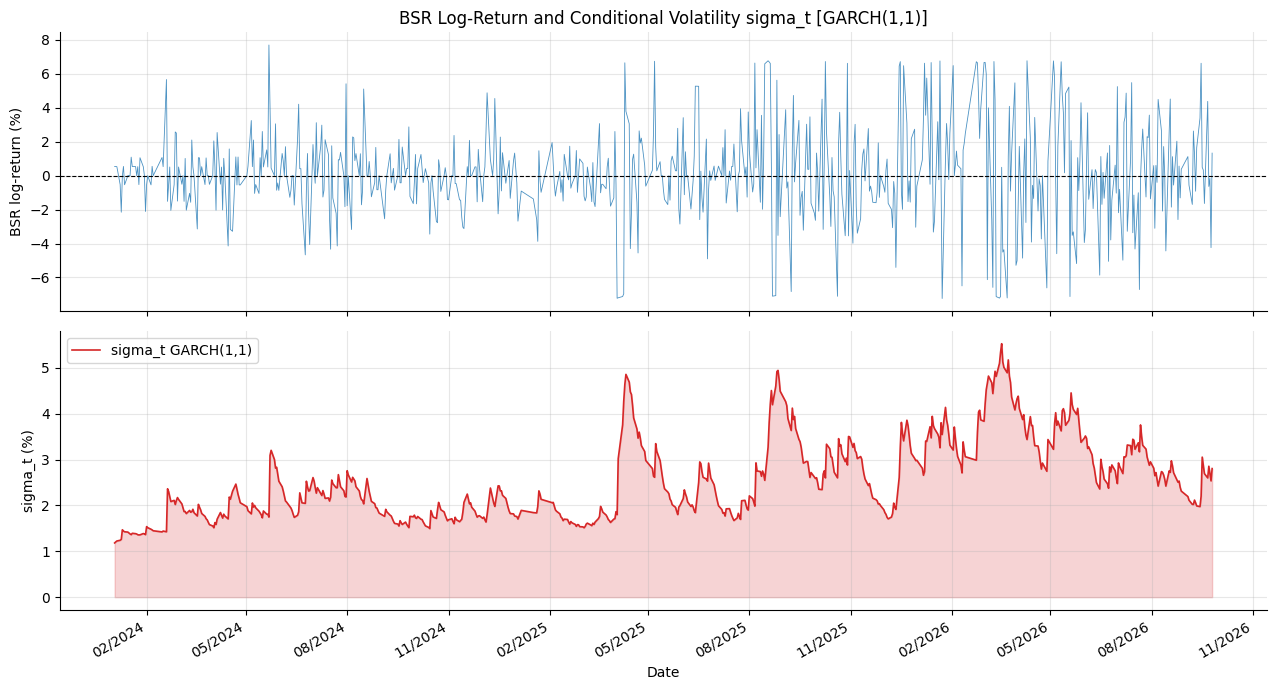

In [12]:
# 3.4 -- Conditional volatility summary + plot
cond_vol = res.conditional_volatility  # sigma_t in %

print("=== Conditional Volatility sigma_t (%) Summary ===")
print(f"  Mean:  {cond_vol.mean():.4f}%")
print(f"  Min:   {cond_vol.min():.4f}%")
print(f"  Max:   {cond_vol.max():.4f}%")
print()

# Top 5 highest vol days
vol_df = pd.DataFrame({"date": df["date"].values, "sigma_t": cond_vol.values})
top5 = vol_df.nlargest(5, "sigma_t")
print("Top 5 highest volatility days:")
for _, row in top5.iterrows():
    print(f"  {row['date'].strftime('%Y-%m-%d')}  sigma_t = {row['sigma_t']:.4f}%")

# Plot -- same time axis as Part 2
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)

# Panel 1: BSR log-return
axes[0].plot(df["date"], df["BSR_log_return"]*100, lw=0.6, color=BLUE, alpha=0.8)
axes[0].axhline(0, color="black", lw=0.8, ls="--")
axes[0].set_ylabel("BSR log-return (%)")
axes[0].set_title("BSR Log-Return and Conditional Volatility sigma_t [GARCH(1,1)]")

# Panel 2: conditional volatility
axes[1].plot(vol_df["date"], vol_df["sigma_t"], lw=1.2, color=RED, label="sigma_t GARCH(1,1)")
axes[1].fill_between(vol_df["date"], vol_df["sigma_t"], alpha=0.2, color=RED)
axes[1].set_ylabel("sigma_t (%)")
axes[1].set_xlabel("Date")
axes[1].legend(loc="upper left")

for ax in axes:
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
plt.gcf().autofmt_xdate()
plt.tight_layout(); plt.show()

In [13]:
# 3.4 -- Model diagnostics: standardised residuals
std_resid = res.resid / res.conditional_volatility

print("=== Standardised Residuals Diagnostics ===")
print(f"  Mean:          {std_resid.mean():.4f}  (expect ~0)")
print(f"  Std:           {std_resid.std():.4f}  (expect ~1)")
print(f"  Skewness:      {std_resid.skew():.4f}")
print(f"  Excess Kurt:   {std_resid.kurt():.4f}")
print()

# Model validity checks
print("=== Model Validity ===")
print(f"  Convergence:   {'OK' if res.convergence_flag == 0 else 'FAILED'}")
print(f"  omega > 0:     {'OK' if omega_g > 0 else 'FAIL'} ({omega_g:.6f})")
print(f"  alpha_1 >= 0:  {'OK' if alpha1_g >= 0 else 'FAIL'} ({alpha1_g:.6f})")
print(f"  beta_1 >= 0:   {'OK' if beta1_g >= 0 else 'FAIL'} ({beta1_g:.6f})")
print(f"  a1+b1 < 1:     {'OK' if persist < 1 else 'FAIL'} ({persist:.6f})")
print(f"  alpha_1 sig:   p={res.pvalues['alpha[1]']:.4f} {'< 0.05 OK' if res.pvalues['alpha[1]'] < 0.05 else '>= 0.05'}")
print(f"  beta_1 sig:    p={res.pvalues['beta[1]']:.2e} {'< 0.05 OK' if res.pvalues['beta[1]'] < 0.05 else '>= 0.05'}")

# ARCH-LM on standardised residuals
from statsmodels.stats.diagnostic import het_arch
lm2, p2, _, _ = het_arch(std_resid.dropna().values, nlags=5)
print(f"\n  ARCH-LM on std resid: LM={lm2:.4f}, p={p2:.4f}")
if p2 > 0.05:
    print("  -> No remaining ARCH effects -> model captures vol dynamics well")
else:
    print("  -> Remaining ARCH effects detected")

=== Standardised Residuals Diagnostics ===
  Mean:          0.0252  (expect ~0)
  Std:           0.9986  (expect ~1)
  Skewness:      0.2525
  Excess Kurt:   1.3374

=== Model Validity ===
  Convergence:   OK
  omega > 0:     OK (0.234411)
  alpha_1 >= 0:  OK (0.115481)
  beta_1 >= 0:   OK (0.853606)
  a1+b1 < 1:     OK (0.969087)
  alpha_1 sig:   p=0.0018 < 0.05 OK
  beta_1 sig:    p=3.93e-65 < 0.05 OK

  ARCH-LM on std resid: LM=5.4591, p=0.3624
  -> No remaining ARCH effects -> model captures vol dynamics well


# KET LUAN

### Phan 1 -- Hoi quy (Beta CAPM)

- Beta duoc uoc luong truc tiep tu OLS regression.
- Dung R2 de phan ra rui ro he thong vs. rui ro dac thu.
- Kiem dinh beta != 0 va beta != 1.

### Phan 2 -- Volatility Clustering

- Chuoi BSR log-return the hien ro rang volatility clustering.
- ARCH-LM test xac nhan su ton tai cua ARCH effects.
- Rui ro thay doi theo thoi gian -> can mo hinh phuong sai co dieu kien.

### Phan 3 -- GARCH(1,1)

- Mo hinh GARCH(1,1) uoc luong conditional volatility theo thoi gian.
- Persistence (alpha_1 + beta_1) cho biet toc do tan cua cu soc.
- Conditional volatility sigma_t dung de tinh VaR, margin, dinh gia quyen chon.
